In [ ]:
#| default_exp vocoder

# Building a vocoder

> HiFi-GAN: log mel -> waveform. Built and trained here, improved in notebook 04.

In the last notebook we turned a waveform into a mel spectrogram and then tried to turn it back with Griffin-Lim. It
worked, in the sense that you could tell what was being said, but it sounded like a robot in a drainpipe. The problem
was phase: the mel spectrogram says how much of each frequency is present in each 12 ms frame, but not how the waves
line up, and Griffin-Lim can only guess.

A **vocoder** is a neural network that learns to do this properly. It takes an 80 × T mel spectrogram and outputs
256 × T audio samples. That's it. It's the second half of every TTS system that predicts spectrograms, and it's also,
structurally, the decoder half of the neural codecs we looked at.

We're going to build one from scratch in PyTorch and train it on this laptop. It won't be as good as one trained for
days on a GPU (we'll load one of those at the end for comparison), but we'll get to hear it go from noise to speech in
about twenty minutes, and, more importantly, we'll find out *why* the obvious way of training it doesn't work.

The architecture we'll build is **HiFi-GAN** (Kong et al., 2020), scaled down. It's the vocoder in Piper, in the
original VITS, in Kokoro (as a variant), and in most things since. Almost nothing about it is mysterious once you've
built it.

In [ ]:
#| export
import time

import numpy as np
import torch
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from torch import nn
from torch.nn.utils.parametrizations import weight_norm

from text_to_speech.audio import log_mel

In [ ]:
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio

from text_to_speech.audio import HOP, SR, griffin_lim
from text_to_speech.core import DATA, default_device
from text_to_speech.data import WAVS

torch.manual_seed(0)
np.random.seed(0)
device = default_device()
print(device)

mps


In [ ]:
checkpoints = DATA / "checkpoints"
checkpoints.mkdir(exist_ok=True)

## Data

A vocoder only needs to see a fraction of a second at a time: what a waveform looks like depends on the mel frames
around it, not on the sentence. So we train on random 8,192-sample segments (0.37 s, exactly 32 mel frames) rather
than whole clips. That also means we don't need much data. We'll load 500 clips, under an hour of speech, into memory
as 16-bit integers and convert to float on the fly.

In [ ]:
files = sorted(WAVS.glob("*.wav"))[:500]
clips = [sf.read(f, dtype="int16")[0] for f in files]
print(f"{len(clips)} clips, {sum(len(c) for c in clips) / SR / 60:.0f} minutes")

500 clips, 55 minutes


In [ ]:
#| export
def random_segments(clips, device, batch_size=16, segment=8192):
    "(batch_size, segment) float tensor in [-1, 1], one random window from each of `batch_size` random int16 clips."
    batch = []
    for _ in range(batch_size):
        clip = clips[np.random.randint(len(clips))]
        start = np.random.randint(0, len(clip) - segment)
        batch.append(clip[start : start + segment])
    return torch.tensor(np.stack(batch), device=device).float() / 32768

In [ ]:
random_segments(clips, device).shape

torch.Size([16, 8192])

## The mel spectrogram, again, in torch

We need the mel spectrogram inside the training loop, on the GPU, differentiable. That's `log_mel`, from the end of
notebook 02. Note its two differences from the numpy version there: reflect padding, so every mel frame lines up with
exactly 256 samples, and HiFi-GAN's conventions (magnitude, Slaney filters), so our mels match the pretrained vocoder
at the end of this notebook.

In [ ]:
y = random_segments(clips, device)
log_mel(y).shape

torch.Size([16, 80, 32])

Before building anything, let's fix our baseline and our test sentence. We'll judge every vocoder on the same full
clip, by ear and by the mean absolute error between the log mel of its output and the log mel of the original. (Using
the mel error to judge a *mel-conditioned* vocoder is a bit circular. Keep that in mind; it's going to bite us shortly.)

In [ ]:
test_audio, _ = sf.read(WAVS / "LJ001-0001.wav", dtype="float32")
test_audio = test_audio[: len(test_audio) // HOP * HOP]  # Trim to a whole number of frames
test_mel = log_mel(torch.tensor(test_audio, device=device)[None])


def mel_error(audio):
    m = log_mel(torch.tensor(audio, device=device)[None])
    n = min(m.shape[-1], test_mel.shape[-1])
    return (m[..., :n] - test_mel[..., :n]).abs().mean().item()


gl = griffin_lim(test_mel[0].cpu().numpy())
print(f"Griffin-Lim mel error: {mel_error(gl):.3f}")
Audio(gl, rate=SR)

Griffin-Lim mel error: 1.495


## The generator

Here's the shape of the problem: 80 numbers per frame in, 256 numbers per frame out. So the network has to
**upsample by 256×** along the time axis, and along the way turn "which frequencies" into "what the wave looks like".

HiFi-GAN does the upsampling in stages using transposed convolutions: 8× then 8× then 2× then 2×. Each stage halves the
number of channels as it doubles (or more) the length, so the tensor stays about the same size. After each upsampling
there's a stack of residual blocks with **dilated** convolutions: a dilation of 3 means the kernel skips over samples,
so a stack of dilations 1, 3, 5 sees a wide window of time with few parameters. That's how a small network gets the
receptive field it needs to build a wave that stays coherent over a whole pitch period.

Everything is wrapped in `weight_norm`, which reparameterises each weight as a direction and a magnitude. It's a cheap
trick that makes GAN training noticeably more stable. Let's build it.

In [ ]:
#| export

class ResBlock(nn.Module):
    "Three dilated conv pairs with residual connections. Same length in, same length out."

    def __init__(self, channels, kernel_size, dilations=(1, 3, 5)):
        super().__init__()
        self.convs1 = nn.ModuleList(
            [
                weight_norm(nn.Conv1d(channels, channels, kernel_size, dilation=d, padding=(kernel_size * d - d) // 2))
                for d in dilations
            ]
        )
        self.convs2 = nn.ModuleList(
            [weight_norm(nn.Conv1d(channels, channels, kernel_size, padding=kernel_size // 2)) for _ in dilations]
        )

    def forward(self, x):
        for c1, c2 in zip(self.convs1, self.convs2):
            x = x + c2(F.leaky_relu(c1(F.leaky_relu(x, 0.1)), 0.1))
        return x


class Generator(nn.Module):
    "(batch, n_mels, frames) -> (batch, 1, frames * prod(rates)) waveform in [-1, 1]."

    def __init__(self, n_mels=80, channels=128, rates=(8, 8, 2, 2), kernels=(16, 16, 4, 4), res_kernels=(3, 7, 11)):
        super().__init__()
        self.conv_pre = weight_norm(nn.Conv1d(n_mels, channels, 7, padding=3))
        self.ups = nn.ModuleList()
        self.resblocks = nn.ModuleList()
        for i, (rate, kernel) in enumerate(zip(rates, kernels)):
            c_in, c_out = channels // 2**i, channels // 2 ** (i + 1)
            self.ups.append(
                weight_norm(nn.ConvTranspose1d(c_in, c_out, kernel, stride=rate, padding=(kernel - rate) // 2))
            )
            for k in res_kernels:
                self.resblocks.append(ResBlock(c_out, k))
        self.n_res = len(res_kernels)
        self.conv_post = weight_norm(nn.Conv1d(channels // 2 ** len(rates), 1, 7, padding=3))

    def forward(self, mel):
        x = self.conv_pre(mel)
        for i, up in enumerate(self.ups):
            x = up(F.leaky_relu(x, 0.1))
            # Average the outputs of the res blocks with different kernel sizes.
            x = sum(self.resblocks[i * self.n_res + j](x) for j in range(self.n_res)) / self.n_res
        return torch.tanh(self.conv_post(F.leaky_relu(x)))

In [ ]:
generator = Generator().to(device)
print(f"{sum(p.numel() for p in generator.parameters()) / 1e6:.2f}M parameters")

mel = log_mel(y)
print(mel.shape, "->", generator(mel).shape)

0.93M parameters
torch.Size([16, 80, 32]) -> torch.Size([16, 1, 8192])


Under a million parameters, and 32 mel frames come out as 8,192 samples. The full-size HiFi-GAN V1 is the same code
with `channels=512`, which makes it 14M parameters; we'll use that at the end.

## Attempt 1: just predict the waveform

The obvious thing to do: compare the generated waveform to the real one, sample by sample, and minimise the difference.
Let's write a generic training loop that takes a loss function, and try it.

In [ ]:
def train(generator, loss_fn, steps, lr=2e-4, log_every=100):
    "Train `generator` to minimise loss_fn(real, fake). Returns the loss history."
    opt = torch.optim.AdamW(generator.parameters(), lr, betas=(0.8, 0.99))
    history, t0 = [], time.time()
    for step in range(1, steps + 1):
        real = random_segments(clips, device)
        fake = generator(log_mel(real)).squeeze(1)
        loss = loss_fn(real, fake)
        opt.zero_grad()
        loss.backward()
        opt.step()
        history.append(loss.item())
        if step % log_every == 0:
            print(f"step {step:>5}  loss {np.mean(history[-log_every:]):.4f}  {time.time() - t0:.0f}s")
    return history


def synthesise(generator, mel=test_mel):
    generator.eval()
    with torch.no_grad():
        out = generator(mel).squeeze().cpu().numpy()
    generator.train()
    return out

In [ ]:
def waveform_l1(real, fake):
    return (real - fake).abs().mean()


generator = Generator().to(device)
history_l1 = train(generator, waveform_l1, steps=500)
out_l1 = synthesise(generator)
print(f"mel error: {mel_error(out_l1):.3f}")
Audio(out_l1, rate=SR)

step   100  loss 0.0449  20s
step   200  loss 0.0433  35s
step   300  loss 0.0434  50s
step   400  loss 0.0434  118s
step   500  loss 0.0439  134s
mel error: 3.306


Have a listen. It's very quiet, and what's there is a dull murmur. Let's look at why.

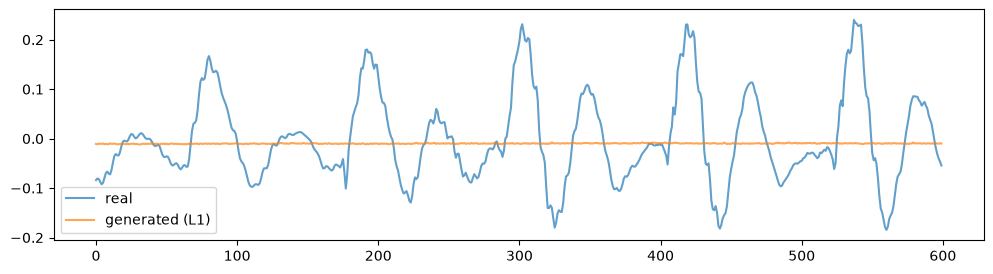

In [ ]:
start = 30_000  # A voiced region of the test clip
plt.figure(figsize=(12, 3))
plt.plot(test_audio[start : start + 600], label="real", alpha=0.7)
plt.plot(out_l1[start : start + 600], label="generated (L1)", alpha=0.7)
plt.legend()
plt.show()

The generator has learned to output something small and smooth. And from the point of view of the loss, that's the
*right answer*.

Here's the thing about phase. Take a pure 100 Hz tone. Shift it by 5 ms, half a cycle. It sounds identical: same pitch,
same loudness, and a mel spectrogram of it is identical too. But sample-by-sample, the shifted version is the exact
negative of the original, so the L1 distance between them is as large as it could possibly be.

Now, the mel spectrogram we feed the generator doesn't say where in its cycle each harmonic is. So for any input, the
"correct" waveform could be any of a whole family of phase-shifted versions, and the generator has no way to know
which one the training example happens to be. Whatever it guesses, it's wrong most of the time. The output that
minimises the *expected* L1 error over all those possibilities is close to zero. So that's what it learns.

This is the fundamental reason vocoders are hard, and it took the field a while to work out. The fix is to stop
comparing waveforms and compare something phase-invariant instead.

## Attempt 2: predict the mel spectrogram

We already have a phase-invariant thing: the mel spectrogram. So generate a waveform, take *its* mel spectrogram, and
compare that to the input. The generator is free to pick any phase it likes, as long as the frequencies come out
right.

In [ ]:
def mel_l1(real, fake):
    return (log_mel(real) - log_mel(fake)).abs().mean()


generator = Generator().to(device)
history_mel = train(generator, mel_l1, steps=1500)
torch.save(generator.state_dict(), checkpoints / "03_generator_mel.pt")

out_mel = synthesise(generator)
print(f"mel error: {mel_error(out_mel):.3f}")
Audio(out_mel, rate=SR)

step   100  loss 1.2555  18s
step   200  loss 0.9974  34s
step   300  loss 0.8982  49s
step   400  loss 0.8462  64s
step   500  loss 0.7973  79s
step   600  loss 0.7723  94s
step   700  loss 0.7504  109s
step   800  loss 0.7287  123s
step   900  loss 0.7111  139s
step  1000  loss 0.6942  154s
step  1100  loss 0.6860  169s
step  1200  loss 0.6701  184s
step  1300  loss 0.6604  199s
step  1400  loss 0.6572  214s
step  1500  loss 0.6505  229s
mel error: 0.663


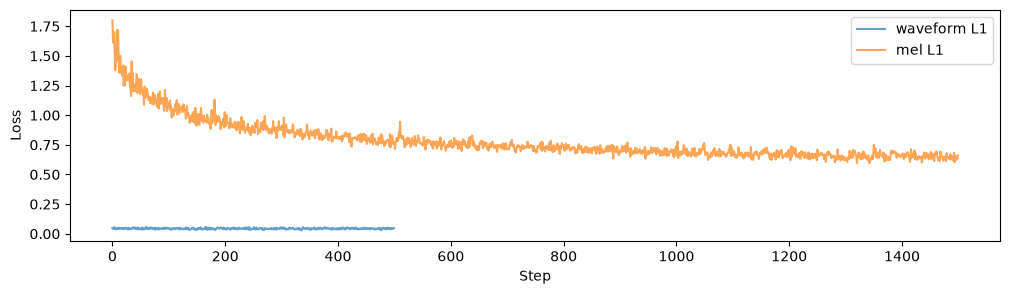

In [ ]:
plt.figure(figsize=(12, 3))
plt.plot(history_l1, label="waveform L1", alpha=0.7)
plt.plot(history_mel, label="mel L1", alpha=0.7)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.show()

Now we're talking. It's clearly speech, and clearly the right words, after three minutes on a laptop. The mel error is
already better than Griffin-Lim. But listen closely: there's a buzzy, metallic edge to it, especially on vowels. Let's
look at the mel spectrograms and the waveforms side by side.

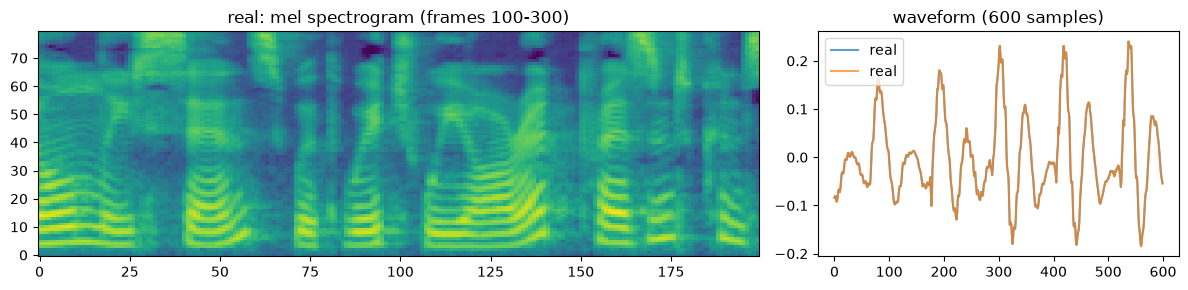

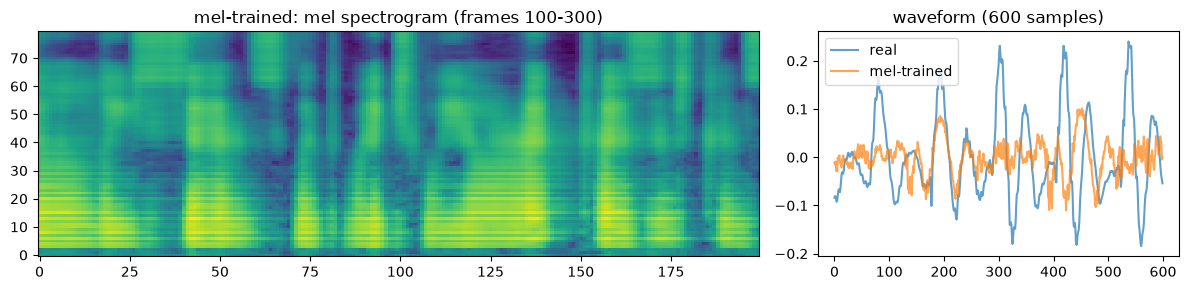

In [ ]:
def compare(audio, label):
    m = log_mel(torch.tensor(audio, device=device)[None])[0].cpu().numpy()
    _fig, axes = plt.subplots(1, 2, figsize=(12, 3), width_ratios=[2, 1])
    axes[0].imshow(m[:, 100:300], origin="lower", aspect="auto", interpolation="nearest")
    axes[0].set_title(f"{label}: mel spectrogram (frames 100-300)")
    axes[1].plot(test_audio[start : start + 600], alpha=0.7, label="real")
    axes[1].plot(audio[start : start + 600], alpha=0.7, label=label)
    axes[1].set_title("waveform (600 samples)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


compare(test_audio, "real")
compare(out_mel, "mel-trained")

The spectrograms are nearly identical. The waveforms are completely different, which is fine and expected: we told the
model phase was free. But the buzz tells us the mel spectrogram is missing something. It's too coarse. Each mel bin
averages a band of frequencies, and each frame averages 46 ms, so there is a lot of room for the fine structure to be
wrong (harmonics slightly off, noise where there should be a clean tone, rough edges between frames) while the mel
looks perfect.

We've hit the limit of the metric. The loss is satisfied and our ears aren't. This is the recurring problem in audio
generation: any hand-designed distance either punishes things that don't matter (phase) or misses things that do.

## Attempt 3: learn the metric

If we can't write down what "sounds real" means, we can train a second network to learn it. That's a GAN. The
**discriminator** takes a chunk of waveform and predicts whether it's real or generated. The generator is trained to
fool it. Whatever the discriminator learns to notice, real or not, the generator has to fix. In practice it learns to
notice exactly the buzz we can hear and the mel loss can't.

HiFi-GAN's key contribution is the design of the discriminators:

- The **multi-period discriminator** reshapes the 1D waveform into a 2D array with a fixed period, say 3, so that
  every 3rd sample ends up in the same column. A 2D conv over that sees periodic structure directly. Five of these with
  periods 2, 3, 5, 7, 11 cover a range of pitches (and since those are primes, they don't overlap).
- The **multi-scale discriminator** is a plain 1D conv net applied to the waveform at full resolution and downsampled
  by 2, so it sees both fine detail and longer-range structure.

Ours are slimmed down from the paper: fewer channels and two scales instead of three, so that a step takes a fraction
of a second on a laptop.

In [ ]:
#| export
class PeriodDiscriminator(nn.Module):
    "Folds the waveform into columns of `period` samples and runs a 2D conv net over them."

    def __init__(self, period, channels=(1, 32, 64, 128, 256)):
        super().__init__()
        self.period = period
        self.convs = nn.ModuleList(
            [
                weight_norm(nn.Conv2d(channels[i], channels[i + 1], (5, 1), (3, 1), padding=(2, 0)))
                for i in range(len(channels) - 1)
            ]
        )
        self.conv_post = weight_norm(nn.Conv2d(channels[-1], 1, (3, 1), padding=(1, 0)))

    def forward(self, x):
        b, c, t = x.shape
        if t % self.period:
            x = F.pad(x, (0, self.period - t % self.period), "reflect")
            t = x.shape[-1]
        x = x.view(b, c, t // self.period, self.period)  # 1D -> 2D: one column per phase within the period
        features = []
        for conv in self.convs:
            x = F.leaky_relu(conv(x), 0.1)
            features.append(x)
        x = self.conv_post(x)
        features.append(x)
        return x.flatten(1), features


class ScaleDiscriminator(nn.Module):
    "A plain 1D conv net over the waveform."

    def __init__(self):
        super().__init__()
        self.convs = nn.ModuleList(
            [
                weight_norm(nn.Conv1d(1, 32, 15, 1, padding=7)),
                weight_norm(nn.Conv1d(32, 64, 41, 4, groups=4, padding=20)),
                weight_norm(nn.Conv1d(64, 128, 41, 4, groups=16, padding=20)),
                weight_norm(nn.Conv1d(128, 256, 41, 4, groups=16, padding=20)),
                weight_norm(nn.Conv1d(256, 256, 5, 1, padding=2)),
            ]
        )
        self.conv_post = weight_norm(nn.Conv1d(256, 1, 3, 1, padding=1))

    def forward(self, x):
        features = []
        for conv in self.convs:
            x = F.leaky_relu(conv(x), 0.1)
            features.append(x)
        x = self.conv_post(x)
        features.append(x)
        return x.flatten(1), features


class Discriminator(nn.Module):
    "All the sub-discriminators. Returns a list of scores and a list of feature maps, one per sub-discriminator."

    def __init__(self, periods=(2, 3, 5, 7, 11), n_scales=2):
        super().__init__()
        self.period_discs = nn.ModuleList([PeriodDiscriminator(p) for p in periods])
        self.scale_discs = nn.ModuleList([ScaleDiscriminator() for _ in range(n_scales)])
        self.pool = nn.AvgPool1d(4, 2, padding=2)

    def forward(self, x):
        scores, features = [], []
        for d in self.period_discs:
            s, f = d(x)
            scores.append(s)
            features.append(f)
        for d in self.scale_discs:
            s, f = d(x)
            scores.append(s)
            features.append(f)
            x = self.pool(x)
        return scores, features

In [ ]:
discriminator = Discriminator().to(device)
print(f"{sum(p.numel() for p in discriminator.parameters()) / 1e6:.2f}M parameters")
scores, features = discriminator(y.unsqueeze(1))
print(len(scores), "sub-discriminators;", "first score shape", tuple(scores[0].shape))

2.00M parameters
7 sub-discriminators; first score shape (16, 102)


Each sub-discriminator outputs a score *per patch of time*, not one score per clip, so it has to justify its verdict
locally.

Now the losses. HiFi-GAN uses the least-squares GAN formulation: the discriminator is pushed to output 1 for real and
0 for fake, and the generator is pushed to make the discriminator output 1. On top of that there are two more terms
for the generator:

- **Feature matching:** the L1 distance between the discriminator's intermediate activations on real and fake audio.
  This is a learned perceptual distance and it stabilises training a lot.
- **Mel loss**, as before, weighted by 45. This keeps the generator honest about *which* frequencies to produce while
  the discriminator handles *how*.

Two optimisers, two backward passes per step. Notice the `.detach()` when training the discriminator: we don't want
its loss to update the generator.

In [ ]:
#| export
def train_mel(generator, clips, steps, lr=2e-4, log_every=100):
    "Train `generator` on the mel loss alone. A head start before the discriminator joins in."
    device = next(generator.parameters()).device
    opt = torch.optim.AdamW(generator.parameters(), lr, betas=(0.8, 0.99))
    for step in range(1, steps + 1):
        mel = log_mel(random_segments(clips, device))
        loss = (log_mel(generator(mel).squeeze(1)) - mel).abs().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % log_every == 0:
            print(f"step {step:>6}  mel {loss.item():.3f}")


def train_gan(generator, discriminator, clips, steps, lr=2e-4, final_lr=None, log_every=100):
    """Train with HiFi-GAN's losses. Returns (steps, 4) history of mel, adversarial, feature matching, discriminator.
    If `final_lr` is given, both learning rates decay exponentially from `lr` to `final_lr` over the run."""
    device = next(generator.parameters()).device
    opt_g = torch.optim.AdamW(generator.parameters(), lr, betas=(0.8, 0.99))
    opt_d = torch.optim.AdamW(discriminator.parameters(), lr, betas=(0.8, 0.99))
    gamma = (final_lr / lr) ** (1 / steps) if final_lr else 1.0
    schedulers = [torch.optim.lr_scheduler.ExponentialLR(opt, gamma) for opt in (opt_g, opt_d)]
    history, t0 = [], time.time()
    for step in range(1, steps + 1):
        real = random_segments(clips, device).unsqueeze(1)
        mel = log_mel(real.squeeze(1))
        fake = generator(mel)

        # Discriminator: real -> 1, fake -> 0.
        real_scores, _ = discriminator(real)
        fake_scores, _ = discriminator(fake.detach())
        loss_d = sum(((1 - r) ** 2).mean() + (f**2).mean() for r, f in zip(real_scores, fake_scores))
        opt_d.zero_grad()
        loss_d.backward()
        opt_d.step()

        # Generator: fool the discriminator, match its features, match the mel.
        _, real_features = discriminator(real)
        fake_scores, fake_features = discriminator(fake)
        loss_adv = sum(((1 - f) ** 2).mean() for f in fake_scores)
        loss_fm = sum(
            (r.detach() - f).abs().mean() for rf, ff in zip(real_features, fake_features) for r, f in zip(rf, ff)
        )
        loss_mel = (log_mel(fake.squeeze(1)) - mel).abs().mean()
        loss_g = loss_adv + 2 * loss_fm + 45 * loss_mel
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()

        for s in schedulers:
            s.step()
        history.append((loss_mel.item(), loss_adv.item(), loss_fm.item(), loss_d.item()))
        if step % log_every == 0:
            m = np.array(history[-log_every:]).mean(0)
            print(
                f"step {step:>6}  mel {m[0]:.3f}  adv {m[1]:.2f}  fm {m[2]:.3f}  disc {m[3]:.2f}  "
                f"lr {schedulers[0].get_last_lr()[0]:.1e}  {time.time() - t0:.0f}s"
            )
    return np.array(history)

`train_mel` is the mel-only training above, packaged for notebook 04. `train_gan`'s `final_lr` is also for notebook 04; we train at a constant rate here.

We'll start from the mel-trained generator rather than from scratch. Giving the generator a head start before the
discriminator arrives is a common trick: a discriminator facing pure noise wins instantly and gives useless gradients.
This takes about a quarter of a second per step on an M-series Mac, so go and make a cup of tea.

In [ ]:
generator = Generator().to(device)
generator.load_state_dict(torch.load(checkpoints / "03_generator_mel.pt"))
discriminator = Discriminator().to(device)

history_gan = train_gan(generator, discriminator, clips, steps=20000)
torch.save(generator.state_dict(), checkpoints / "03_generator_gan.pt")

out_gan = synthesise(generator)
print(f"mel error: {mel_error(out_gan):.3f}")
Audio(out_gan, rate=SR)

step   100  mel 0.661  adv 2.33  fm 0.561  disc 3.56  51s
step   200  mel 0.643  adv 3.10  fm 2.469  disc 2.46  85s
step   300  mel 0.646  adv 3.31  fm 2.679  disc 2.37  127s
step   400  mel 0.637  adv 3.31  fm 2.687  disc 2.35  164s
step   500  mel 0.669  adv 3.21  fm 2.536  disc 2.42  198s
step   600  mel 0.673  adv 3.22  fm 2.562  disc 2.40  231s
step   700  mel 0.669  adv 3.22  fm 2.570  disc 2.41  265s
step   800  mel 0.663  adv 3.23  fm 2.604  disc 2.40  298s
step   900  mel 0.666  adv 3.22  fm 2.663  disc 2.37  331s
step  1000  mel 0.659  adv 3.23  fm 2.731  disc 2.34  365s
step  1100  mel 0.655  adv 3.24  fm 2.772  disc 2.34  398s
step  1200  mel 0.679  adv 3.29  fm 2.798  disc 2.55  432s
step  1300  mel 0.643  adv 3.16  fm 2.684  disc 2.41  465s
step  1400  mel 0.631  adv 3.24  fm 2.807  disc 2.34  499s
step  1500  mel 0.632  adv 3.26  fm 2.875  disc 2.34  532s
step  1600  mel 0.633  adv 3.25  fm 2.862  disc 2.37  566s
step  1700  mel 0.627  adv 3.21  fm 2.849  disc 2.39  599s

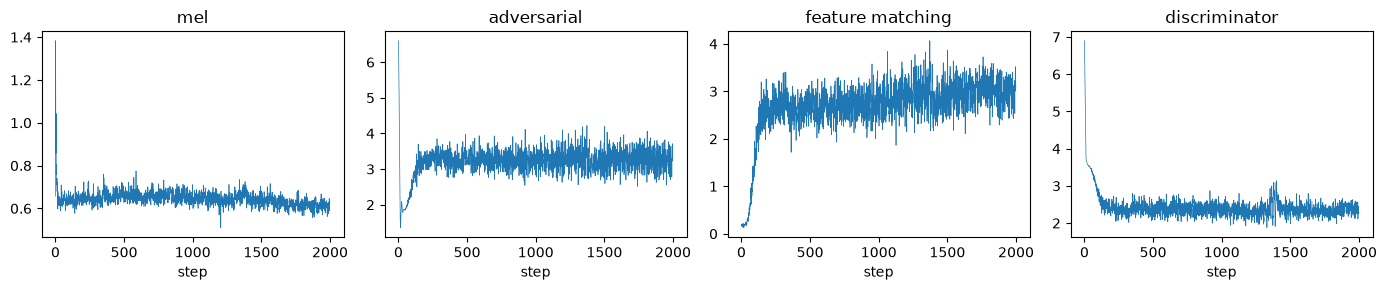

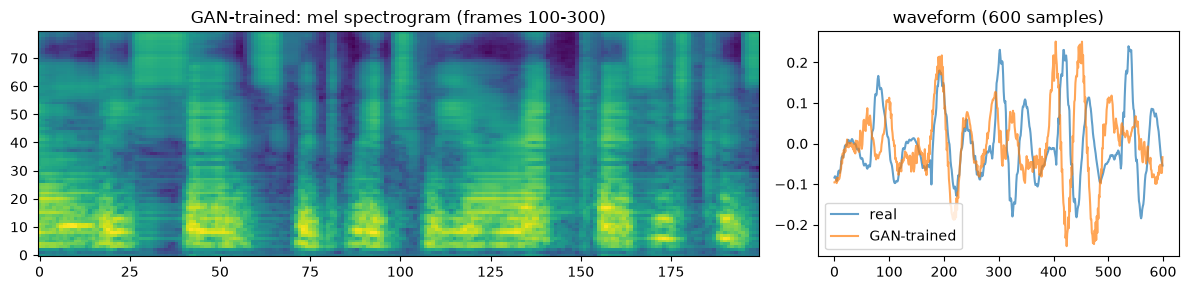

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col, name in zip(axes, history_gan.T, ["mel", "adversarial", "feature matching", "discriminator"]):
    ax.plot(col, lw=0.5)
    ax.set_title(name)
    ax.set_xlabel("step")
plt.tight_layout()
plt.show()

compare(out_gan, "GAN-trained")

The mel error may not have improved much, and might even be slightly worse. That's the whole point of the last hour:
the mel error can't hear the buzz. Trust your ears here. The adversarial and discriminator losses don't trend to zero
and shouldn't: they measure a tug of war, and a healthy GAN sits somewhere in the middle. Piper's docs say the same
thing about its `loss_disc_all`: don't stare at it.

## What a real one sounds like

Our vocoder has trained for 3,500 steps. The HiFi-GAN paper trains for 2.5 *million*, on a V100 GPU, for several
days. Let's see what that buys. SpeechBrain publish a HiFi-GAN V1 trained on LJSpeech, and it's exactly our
`Generator` class with `channels=512`, so we can load its weights straight in. The only fiddle is that it was saved
with the old-style `weight_norm`, which names its parameters differently.

In [ ]:
#| export
def pretrained_hifigan():
    "SpeechBrain's LJSpeech HiFi-GAN, loaded into our `Generator`. Same architecture, 4x the channels."
    state = torch.load(hf_hub_download("speechbrain/tts-hifigan-ljspeech", "generator.ckpt"), map_location="cpu")

    def rename(key):
        return (
            key.replace(".conv.weight_g", ".parametrizations.weight.original0")
            .replace(".conv.weight_v", ".parametrizations.weight.original1")
            .replace(".conv.bias", ".bias")
        )

    generator = Generator(channels=512)
    generator.load_state_dict({rename(k): v for k, v in state.items()})
    return generator.eval()

In [ ]:
pretrained = pretrained_hifigan().to(device)
print(f"{sum(p.numel() for p in pretrained.parameters()) / 1e6:.1f}M parameters")

out_pretrained = synthesise(pretrained)
print(f"mel error: {mel_error(out_pretrained):.3f}")
Audio(out_pretrained, rate=SR)

13.9M parameters
mel error: 0.348


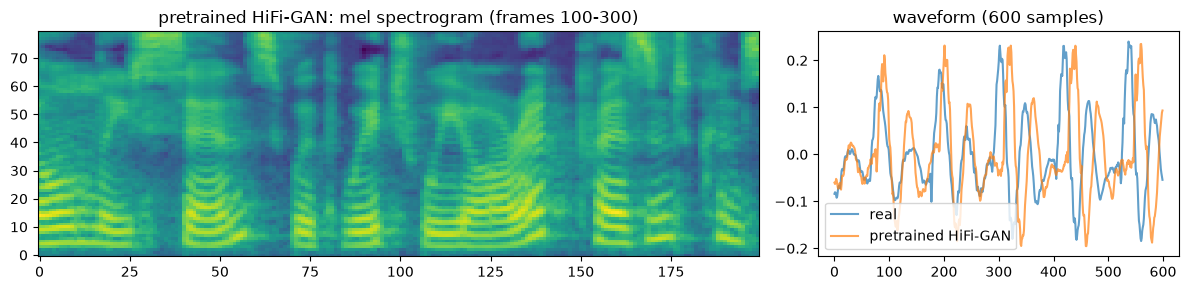

Griffin-Lim            mel error 1.495
waveform L1            mel error 3.306
mel L1                 mel error 0.663
GAN                    mel error 0.646
pretrained HiFi-GAN    mel error 0.348


In [ ]:
compare(out_pretrained, "pretrained HiFi-GAN")

for name, audio in [
    ("Griffin-Lim", gl),
    ("waveform L1", out_l1),
    ("mel L1", out_mel),
    ("GAN", out_gan),
    ("pretrained HiFi-GAN", out_pretrained),
]:
    print(f"{name:<22} mel error {mel_error(audio):.3f}")

Indistinguishable from the recording, to my ears. Notice that the pretrained waveform *still* doesn't match the real
one sample for sample. It doesn't need to.

## How much compute is that?

Let's put numbers on the gap between our laptop run and the real thing.

| | steps | batch | hardware | time |
|---|---|---|---|---|
| ours | 3,500 | 16 × 0.37 s | M-series laptop | ~20 min |
| HiFi-GAN V1 paper | 2,500,000 | 16 × 0.37 s | 1 × V100 | ~2 weeks |
| Piper's vocoder (inside VITS) | ~1,000,000 | 32 × 0.37 s | 1 × RTX 3090 | days |

So the paper used about 700× more steps than we did, with a 15× bigger model. At a rented GPU's $0.35 to $2 an hour,
a full HiFi-GAN training run costs on the order of $100 to $500. This is the part of a TTS system where compute buys
the most audible quality, and it's the part you rent a GPU for. Everything before it in this series ran on a laptop.

The good news is that a vocoder is a general-purpose thing. It learns "how does a mel spectrogram of *this speaker*
turn into sound", and to a decent extent "how does *any* mel spectrogram turn into sound". Train it once, or borrow
one, and reuse it under every text-to-mel model you build.

## Summary

- A vocoder upsamples an 80 × T mel spectrogram to 256 × T samples with transposed convolutions and dilated residual
  blocks. Under a million parameters is enough to produce speech.
- You cannot train it with a waveform loss, because the mel spectrogram doesn't determine phase and the model
  collapses to near-silence.
- A mel loss gets you intelligible speech in minutes. It also gets you buzz, because the mel spectrogram is too coarse
  to distinguish clean harmonics from rough ones.
- A discriminator learns the distance you couldn't write down. HiFi-GAN's multi-period and multi-scale discriminators,
  plus feature matching, are what make neural TTS sound like a person.
- The metric you train against and the thing you care about are not the same, and the gap is where all the
  interesting problems live.

## Things to try

- Train the mel-only model for 5,000 steps instead of 1,500. Does the buzz go away, or just get quieter?
- Drop the multi-period discriminator and keep only the multi-scale one, or vice versa. Which one is doing the work?
- Set the mel loss weight to 0 in `train_gan`. What happens in the first 200 steps?
- Feed the pretrained vocoder a mel spectrogram from a *different* speaker (record yourself with notebook 00). How
  much of the voice is in the mel, and how much in the vocoder?
- Feed it a mel spectrogram you've edited: zero out the top 20 bins, or shift all the bins up by 5. What do you hear?